In [1]:
import os
os.chdir("..")

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from optimizer import grid_search, strategy_compare

In [3]:
STRATEGIES = {
    "BuyHold": {"minimum_profit": np.inf},
    "Default": {},
    "Experimental1": {"buy_embargo": 90.0},
}

In [4]:
df_prices = pd.read_csv("data/test_crypto.csv", index_col=0, parse_dates=True)
df_prices.drop("DOGE", axis=1, inplace=True)
df_prices

,BTC,ETH,SOL,XRP,ADA,DOT,LINK,XLM,XMR
Date,,,,,,,,,
2014-09-17,457.334015,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-18,424.440002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-19,394.795990,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-20,408.903992,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-21,398.821014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...
2026-10-20,82941.000000,2446.730713,106.422340,1.334452,0.223782,1.149771,12.320927,0.181960,600.929504
2026-10-21,84011.968750,2470.766113,106.793655,1.363619,0.224979,1.141323,12.484719,0.183488,622.434082
2026-10-22,81311.890625,2386.189209,103.542320,1.307656,0.212025,1.111869,11.943166,0.175209,600.638428


# COMPARE

In [5]:
history_compare = strategy_compare(
    prices=df_prices,
    strategies=STRATEGIES,
    n_boot=100,
    sample_size=10,
    sequence_length=365 * 4,
)

100%|██████████| 3/3 [02:15<00:00, 45.15s/it]


In [6]:
history_compare

,strategy,Target,Cash_spent,Realized_cash,Portfolio,Invested,Total_value,Bull_history,Avg_price,Num_take_profits,MDD,MA200_survival_days,RoAC,iteration
0,BuyHold,SOL,2326,0,4820,2326,4820,87,35.704592,0,-11529,0.000000,303,1
1,BuyHold,SOL,2069,0,46506,2069,46506,99,7.428861,0,-59633,132.000000,666,1
2,BuyHold,XMR,2059,0,3421,2059,3421,38,172.164901,0,-1996,38.294118,-4,1
3,BuyHold,SOL,2059,0,21893,2059,21893,91,13.411137,0,-28299,117.750000,418,1
4,BuyHold,XRP,2326,0,4043,2326,4043,61,0.283749,0,-10451,49.000000,19,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2995,Experimental1,ADA,3217,3270,2589,1717,5859,33,0.463021,1,-2625,210.333333,-20,100
2996,Experimental1,XMR,2059,2453,1505,868,3958,76,236.834545,2,-1174,60.200000,11,100
2997,Experimental1,XMR,2455,2653,1286,1403,3940,62,162.537048,5,-512,41.000000,87,100
2998,Experimental1,SOL,2455,9133,892,307,10026,73,53.088088,9,-1408,69.666667,329,100


In [7]:
compare_res = history_compare.groupby("strategy").agg(
    RoAC=("RoAC", "mean"),
    MDD=("MDD", "mean"),
    Portfolio=("Portfolio", "mean"),
    Realized_cash=("Realized_cash", "mean"),
    Cash_spent=("Cash_spent", "mean"),
    Total_value_mean=("Total_value", "mean"),
    Total_value_median=("Total_value", "median"),
    Total_value_low=("Total_value", lambda s: np.percentile(s, 25)),
    Total_value_high=("Total_value", lambda s: np.percentile(s, 75)),
)

compare_res['Uncle'] = compare_res['MDD'] / compare_res['Total_value_mean']
compare_res['Profit_coef'] = compare_res['Total_value_mean'] / compare_res['Cash_spent']
compare_res.sort_values("RoAC", ascending=False).style.background_gradient(cmap="RdYlGn", axis=0).format("{:.2f}")

,RoAC,MDD,Portfolio,Realized_cash,Cash_spent,Total_value_mean,Total_value_median,Total_value_low,Total_value_high,Uncle,Profit_coef
strategy,,,,,,,,,,,
BuyHold,89.41,-12565.30,7244.32,0.00,2294.68,7244.32,4083.50,2493.50,7812.50,-1.73,3.16
Default,71.38,-1385.68,1177.97,3964.58,2373.84,5143.00,4668.00,3447.00,6133.50,-0.27,2.17
Experimental1,70.11,-1495.66,1232.94,4249.01,2537.64,5482.42,4756.00,3424.50,6612.00,-0.27,2.16


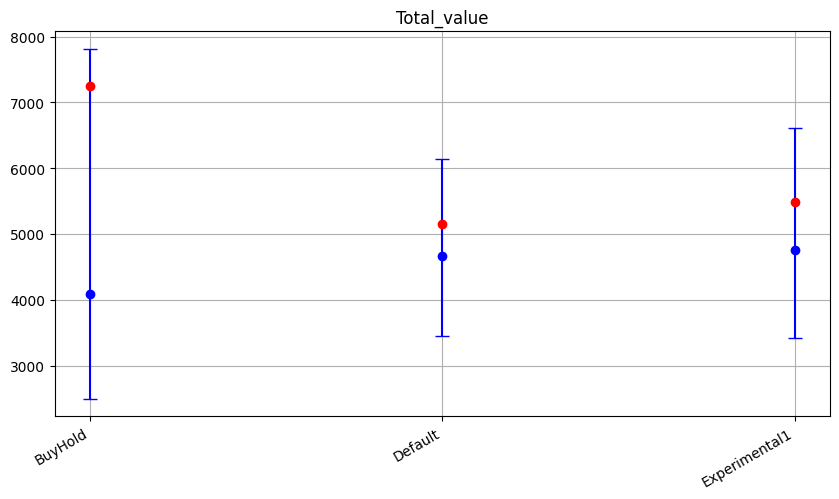

In [8]:
metric = "Total_value"

plt.figure(figsize=(10, 5))

median = compare_res[f"{metric}_median"]
mean = compare_res[f"{metric}_mean"]
low = compare_res[f"{metric}_low"]
high = compare_res[f"{metric}_high"]

plt.errorbar(
    median.index,
    median.values,
    yerr=[median - low, high - median],
    fmt="o",
    capsize=5,
    label="median",
    color="blue",
)
plt.errorbar(
    mean.index,
    mean.values,
    fmt="o",
    capsize=5,
    label="mean",
    color="red",
)
plt.title(metric)
plt.xticks(rotation=30, ha="right")
plt.grid()
plt.show()